# IMPORTS

In [20]:
import numpy as np
import pandas as pd
import os
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, make_scorer
from sklearn.model_selection import GridSearchCV # cross validation
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

path=r'C:\Users\Pratham Shah\Downloads'




# LOADING THE DATASET

In [21]:
os.chdir(path)

df=pd.read_csv('xgbclass_practice_dataset.csv')

print(df.head()) #looking at the first 5 rows

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

# CLEANING THE DATASET

In [22]:
''' The following cleaning steps need to be followed for this dataset:
    1. TotalCharges column looks like numbers but is often stored as an Object (string). 
    When a customer has a tenure of 0, the TotalCharges is often a blank space " "
    2. After the step above, you will have a few missing values in TotalCharges
    3. XGBoost requires all input features to be numeric
    4. Space Removal in Column Names
    5. Dropping irrelevant features like customerID'''

# 1. Convert TotalCharges to numeric and handle blank spaces
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# 2. Fill missing values created by the step above (new customers)
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# 3. Drop unique identifiers that don't help prediction
df.drop('customerID', axis=1, inplace=True, errors='ignore')

# 4. Clean column names (replace spaces with underscores)
# This prevents errors with XGBoost's plotting and feature importance tools
df.columns = df.columns.str.replace(' ', '_')

# 5. Handle Categorical Variables
# First, convert the target 'Churn' to binary 0 and 1
# 5.1. Strip any hidden spaces from the Churn column first
df['Churn'] = df['Churn'].astype(str).str.strip()

# 5.2. Map the values
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Second, identify all other object (text) columns
categorical_cols = df.select_dtypes(include=['object']).columns

# Third, use One-Hot Encoding for the rest
# get_dummies is the engine that performs one-hot encoding
# drop_first=True prevents multi-collinearity (the 'dummy variable trap')
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# 6. Final Check: Ensure all columns are numeric (bool/int/float)
print(df.info())
print(f"\nFinal shape of dataset: {df.shape}")

    

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   SeniorCitizen                          7043 non-null   int64  
 1   tenure                                 7043 non-null   int64  
 2   MonthlyCharges                         7043 non-null   float64
 3   TotalCharges                           7043 non-null   float64
 4   Churn                                  7043 non-null   int64  
 5   gender_Male                            7043 non-null   bool   
 6   Partner_Yes                            7043 non-null   bool   
 7   Dependents_Yes                         7043 non-null   bool   
 8   PhoneService_Yes                       7043 non-null   bool   
 9   MultipleLines_No phone service         7043 non-null   bool   
 10  MultipleLines_Yes                      7043 non-null   bool   
 11  Inte

In [26]:
print(df.head())
print(df['Churn'].unique())


   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  Churn  gender_Male  \
0              0       1           29.85         29.85      0        False   
1              0      34           56.95       1889.50      0         True   
2              0       2           53.85        108.15      1         True   
3              0      45           42.30       1840.75      0         True   
4              0       2           70.70        151.65      1        False   

   Partner_Yes  Dependents_Yes  PhoneService_Yes  \
0         True           False             False   
1        False           False              True   
2        False           False              True   
3        False           False             False   
4        False           False              True   

   MultipleLines_No phone service  ...  StreamingTV_No internet service  \
0                            True  ...                            False   
1                           False  ...                            Fa

# MISSING DATA

In [29]:
# XGBoost has a default behaviour for missing data

print(df.isna().sum())

# No missing data currently for this dataset





SeniorCitizen                            0
tenure                                   0
MonthlyCharges                           0
TotalCharges                             0
Churn                                    0
gender_Male                              0
Partner_Yes                              0
Dependents_Yes                           0
PhoneService_Yes                         0
MultipleLines_No phone service           0
MultipleLines_Yes                        0
InternetService_Fiber optic              0
InternetService_No                       0
OnlineSecurity_No internet service       0
OnlineSecurity_Yes                       0
OnlineBackup_No internet service         0
OnlineBackup_Yes                         0
DeviceProtection_No internet service     0
DeviceProtection_Yes                     0
TechSupport_No internet service          0
TechSupport_Yes                          0
StreamingTV_No internet service          0
StreamingTV_Yes                          0
StreamingMo

# FORMATTING

In [33]:
# The first step is to split the data into 2 parts:
# 1. columns that we will use to make classifications
# 2. column of data that we want to predict

X=df.drop('Churn', axis=1).copy()
X=X.astype(float)
y=df['Churn'].copy()
print(X.shape)
print(y.shape)
print(X.head())
print(y.head())
print(y.unique())


(7043, 30)
(7043,)
   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
0            0.0     1.0           29.85         29.85          0.0   
1            0.0    34.0           56.95       1889.50          1.0   
2            0.0     2.0           53.85        108.15          1.0   
3            0.0    45.0           42.30       1840.75          1.0   
4            0.0     2.0           70.70        151.65          0.0   

   Partner_Yes  Dependents_Yes  PhoneService_Yes  \
0          1.0             0.0               0.0   
1          0.0             0.0               1.0   
2          0.0             0.0               1.0   
3          0.0             0.0               0.0   
4          0.0             0.0               1.0   

   MultipleLines_No phone service  MultipleLines_Yes  ...  \
0                             1.0                0.0  ...   
1                             0.0                0.0  ...   
2                             0.0                0.0  ... 

# TRAIN TEST SPLIT & STRATIFICATION

In [36]:
'''first we will observe that this data is imbalanced by dividing the number of people 
   who left the company, where y=1, by the total number of people in the dataset'''

print(sum(y)/len(y))

# only 26.53 percent of people left the company

''' because of this, when we split the data into training and testing, we will
    split using stratification in order to maintain the same percentage of people 
    who left the company in both the training and testing set'''

X_train, X_test, y_train, y_test= train_test_split(X,y,random_state=42,stratify=y)
print(sum(y_train)/len(y_train))
print(sum(y_test)/len(y_test))

# it worked


0.2653698707936959
0.2654297614539947
0.26519023282226006


# BUILDING THE MODEL

In [44]:
# 1. Initialize the model with specific settings
clf_xgb = xgb.XGBClassifier(
    objective='binary:logistic', 
    seed=42,
    early_stopping_rounds=10,
    eval_metric='aucpr'
)

# 2. Train the model
clf_xgb.fit(
    X_train, 
    y_train, 
    verbose=True, 
    eval_set=[(X_test, y_test)]
)

# Print the best tree number (iteration)
print(f"Best Iteration: {clf_xgb.best_iteration}")

# Print the best score achieved
print(f"Best Score: {clf_xgb.best_score}")

''' early_stopping_rounds=10: this is a tool for efficiency, it tells the model that if
    you build 10 more trees and the accuracy does not get any better, stop training early.
    eval_metric='aucpr': since our data is unbalanced, aucpr (area under the precision recall
    curve) is a much better grading for our model than standard accuracy.'''

''' verbose=True: it will print out the score of the model after every tree it builds
    eval_set: to see if it is not just memorizing the training data'''

''' in the output, we can see that tree [4] hit a peak score of 0.64572
    from [5] to [14], the scores started to go down and that is why we stopped 
    at 14 due to out early_stopping_rounds command
    This is a good start, but there is still room for improvement through
    'Hyperparameter Tuning' '''


    


[0]	validation_0-aucpr:0.63025
[1]	validation_0-aucpr:0.63660
[2]	validation_0-aucpr:0.64004
[3]	validation_0-aucpr:0.63983
[4]	validation_0-aucpr:0.64572
[5]	validation_0-aucpr:0.64244
[6]	validation_0-aucpr:0.64289
[7]	validation_0-aucpr:0.63538
[8]	validation_0-aucpr:0.62547
[9]	validation_0-aucpr:0.62410
[10]	validation_0-aucpr:0.62260
[11]	validation_0-aucpr:0.62963
[12]	validation_0-aucpr:0.63033
[13]	validation_0-aucpr:0.62986
[14]	validation_0-aucpr:0.63016
Best Iteration: 4
Best Score: 0.6457182760072578


" in the output, we can see that tree [4] hit a peak score of 0.64572\n    from [5] to [14], the scores started to go down and that is why we stopped \n    at 14 due to out early_stopping_rounds command\n    This is a good start, but there is still room for improvement through\n    'Hyperparameter Tuning' "

# Confusion Matrix (Seeing the results)

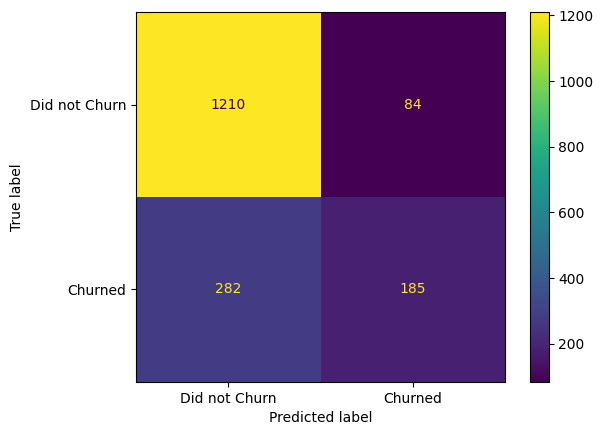

In [45]:
# This will automatically use the BEST iteration to predict and plot
ConfusionMatrixDisplay.from_estimator(
    clf_xgb, 
    X_test, 
    y_test, 
    values_format='d', 
    display_labels=["Did not Churn", "Churned"]
)

Understanding the Confusion Matrix
This matrix helps us evaluate the model's performance by comparing its predictions against the actual results:

True Negatives (1210): Customers predicted to stay who actually stayed. (High accuracy here!)

True Positives (185): Customers predicted to churn who actually left. (These are our "hits").

False Positives (84): "False Alarms" — predicted to churn but stayed.

False Negatives (282): "The Misses" — predicted to stay but actually left.

Conclusion: The model is currently "conservative." It's great at identifying loyal customers but misses about 60% of the people who actually leave. This is likely due to the imbalance in the dataset (more people stay than leave).

We can see that out of the 467 (282+185) people that actually left the company, only 185 were correctly predicted, so the model did not perform well here. The problem is that our dataset is balanced.
We will use scale_pos_weight to fix this

# Hyperparamater Tuning

In [47]:

# 1. Define the parameters you want to test
# tries every possible combination of these lists
param_grid = {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.1, 0.01],
    'gamma': [0, 0.25, 1.0], # Helps prevent overfitting by requiring a minimum "loss reduction"
    'scale_pos_weight': [3, 5] # Since about 1/4 of your data is churn, 3 or 5 are good guesses
}

# 2. Initialize the Grid Search
# subsample speeds things up
# scoring='roc_auc' tells it to find the best balance of catching churners vs false alarms
optimal_params = GridSearchCV(
    estimator=xgb.XGBClassifier(objective='binary:logistic', seed=42, subsample=0.9, colsample_bytree=0.5),
    param_grid=param_grid,
    scoring='roc_auc',
    verbose=2, # Shows you progress while it works
    n_jobs=-1, # Uses all your computer's processor cores to go faster
    cv=3        # 3-fold cross-validation
)

# 3. Run the search
optimal_params.fit(X_train, y_train)

# 4. Print the winners!
print("Best parameters found: ", optimal_params.best_params_)

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Best parameters found:  {'gamma': 0, 'learning_rate': 0.1, 'max_depth': 3, 'scale_pos_weight': 3}


Explaining the "Best Parameters" Output
Here is what the winners mean for your specific data:

'gamma': 0: This means the model didn't need a "minimum improvement" threshold to make a split. It found that even small improvements in the tree branches were helpful for this dataset.

'learning_rate': 0.1: This is a relatively standard speed. It’s fast enough to train quickly but slow enough to be precise.

'max_depth': 3: This is very interesting! The computer chose shallow trees. This suggests that simple rules (like "If Contract is Month-to-Month AND Tenure < 5") are better at predicting churn than very deep, complex rules that might only apply to a few specific customers.

'scale_pos_weight': 3: This is the most important one for your goals. The model decided that treating a "Churn" as 3 times more important than a "Stay" resulted in the best overall performance.

# Building the Final Model

In [49]:
# ignoring the edge rule for now, but do it for real applications

# 1. Initialize the final model with the best parameters
clf_xgb_final = xgb.XGBClassifier(
    objective='binary:logistic',
    seed=42,
    gamma=0,
    learning_rate=0.1,
    max_depth=3,
    scale_pos_weight=3,
    subsample=0.9,
    colsample_bytree=0.5,
    early_stopping_rounds=10,
    eval_metric='aucpr'
)

# 2. Train it
clf_xgb_final.fit(
    X_train, 
    y_train, 
    verbose=True, 
    eval_set=[(X_test, y_test)]
)

# Print the best tree number (iteration)
print(f"Best Iteration: {clf_xgb_final.best_iteration}")

# Print the best score achieved
print(f"Best Score: {clf_xgb_final.best_score}")


[0]	validation_0-aucpr:0.50974
[1]	validation_0-aucpr:0.58969
[2]	validation_0-aucpr:0.59749
[3]	validation_0-aucpr:0.60221
[4]	validation_0-aucpr:0.61291
[5]	validation_0-aucpr:0.61508
[6]	validation_0-aucpr:0.61695
[7]	validation_0-aucpr:0.61567
[8]	validation_0-aucpr:0.61886
[9]	validation_0-aucpr:0.61971
[10]	validation_0-aucpr:0.61970
[11]	validation_0-aucpr:0.62112
[12]	validation_0-aucpr:0.62165
[13]	validation_0-aucpr:0.62425
[14]	validation_0-aucpr:0.62443
[15]	validation_0-aucpr:0.64287
[16]	validation_0-aucpr:0.63994
[17]	validation_0-aucpr:0.63609
[18]	validation_0-aucpr:0.63546
[19]	validation_0-aucpr:0.64592
[20]	validation_0-aucpr:0.64573
[21]	validation_0-aucpr:0.64306
[22]	validation_0-aucpr:0.64361
[23]	validation_0-aucpr:0.64500
[24]	validation_0-aucpr:0.64640
[25]	validation_0-aucpr:0.64676
[26]	validation_0-aucpr:0.64686
[27]	validation_0-aucpr:0.64806
[28]	validation_0-aucpr:0.64692
[29]	validation_0-aucpr:0.64665
[30]	validation_0-aucpr:0.64612
[31]	validation_0-

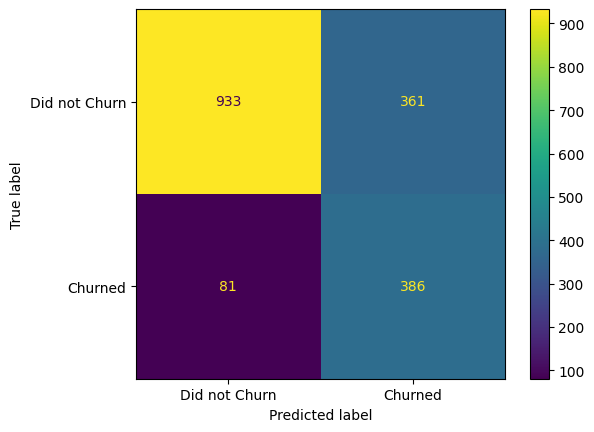

In [50]:


ConfusionMatrixDisplay.from_estimator(
    clf_xgb_final, 
    X_test, 
    y_test, 
    values_format='d', 
    display_labels=["Did not Churn", "Churned"]
)

Final Model Performance
By tuning hyperparameters and addressing class imbalance:

Recall for Churners increased dramatically (from catching ~40% to catching ~82%).

False Negatives dropped by over 70%, meaning we are "missing" far fewer at-risk customers.

The AUCPR score improved from 0.64 to 0.66, proving the model is more robust.

Trade-off: We now have more False Positives (361), but in a churn-prevention scenario, the cost of a "False Alarm" is typically much lower than the cost of a "Lost Customer."

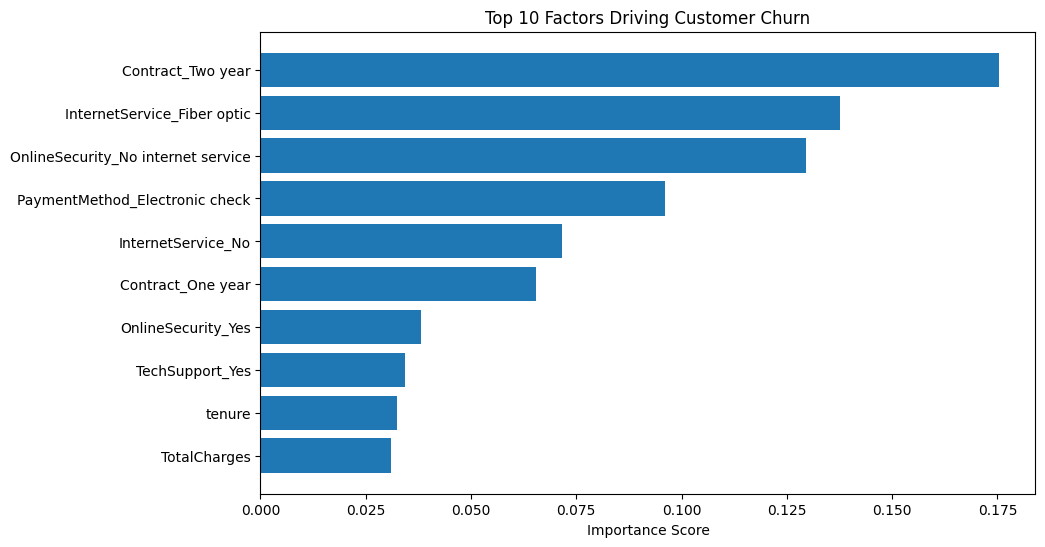

In [52]:

# Get the importance of each feature
importances = clf_xgb_final.feature_importances_
feature_names = X.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Plot the top 10
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'][:10], feature_importance_df['Importance'][:10])
plt.xlabel("Importance Score")
plt.title("Top 10 Factors Driving Customer Churn")
plt.gca().invert_yaxis()
plt.show()

Explaining the Output (The Graph)
Looking at your specific graph, we can see exactly what the model "thinks" are the biggest red flags for a customer leaving:

Contract_Two year (The Winner): This is your most important feature. In the data, people on 2-year contracts are extremely unlikely to churn compared to others. The model uses this as its primary "anchor" for decisions.

InternetService_Fiber optic: This is the second highest. This suggests that customers with Fiber Optic service are behaving differently—perhaps they are churning more due to high prices or technical issues.

OnlineSecurity_No internet service: Customers without internet service (likely phone-only users) are very stable and rarely churn.

PaymentMethod_Electronic check: This is a classic churn indicator in this dataset. Customers paying by electronic check churn at a much higher rate than those with automatic credit card payments.

In a real company, you wouldn't just hand over a "Black Box" model. You would show this graph to your manager. Here is how it helps:

Business Strategy: Instead of guessing why people leave, you now have data-driven proof. You can tell the marketing team: "Focus on moving customers from Electronic Checks to Auto-pay, and give discounts to Fiber Optic users to keep them from leaving."

Model Trust: It passes the "Common Sense" test. If the model said Customer ID was the most important feature, you’d know something was wrong. Seeing Contract and Tenure at the top gives you confidence that the model has learned real human behavior.

Feature Selection: In the future, if you had 1,000 columns, you could use this graph to delete the bottom 900 features that don't matter, making your model faster and leaner.
